In [1]:
# Importing the libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
import pyarrow

from sklearn.metrics import ConfusionMatrixDisplay

In [2]:
# load daily basin gwl
df = pd.read_parquet(r"data\model_dfs\basin_gwl_daily.parquet")

In [3]:
df.columns

Index(['date', 'basin_swe', 'basin_precip_increment', 'n_snow_stations',
       'swe_30d_lag', 'swe_60d_lag', 'swe_90d_lag', 'temp_mean',
       'temp_mean_lag1', 'temp_7d_mean', 'temp_14d_mean', 'precipitation',
       'precip_lag1', 'precip_7d', 'precip_14d', 'precip_30d', 'precip_90d',
       'precip_180d', 'temp_precip_interaction', 'doy_sin', 'doy_cos',
       'n_climate_stations', 'gwl'],
      dtype='object')

In [4]:
df['date'] = pd.to_datetime(df['date'])
df['month'] = df['date'].dt.month

# Seasonal groundwater drought threshold
df['gwl_drought_threshold'] = (
    df.groupby('month')['gwl']
      .transform(lambda x: x.quantile(0.80))
)

# High groundwater depth = low water table = drought
df['target'] = (
    df['gwl'] >= df['gwl_drought_threshold']
).astype(int)

In [5]:
df['date'] = pd.to_datetime(df['date'])
df['month'] = df['date'].dt.month

df['snow_month'] = df['month'].isin([11, 12, 1, 2, 3, 4, 5]).astype(int)


In [6]:
df.groupby('target')[[
    'basin_swe',
    'temp_mean',
    'temp_14d_mean',
    'precip_7d',
    'precip_14d',
    'precip_30d'
]].mean()

,basin_swe,temp_mean,temp_14d_mean,precip_7d,precip_14d,precip_30d
target,,,,,,
0,5.716027,43.844948,43.80840,0.228658,0.456987,0.981612
1,5.941904,42.415478,42.63161,0.259588,0.517127,1.088644


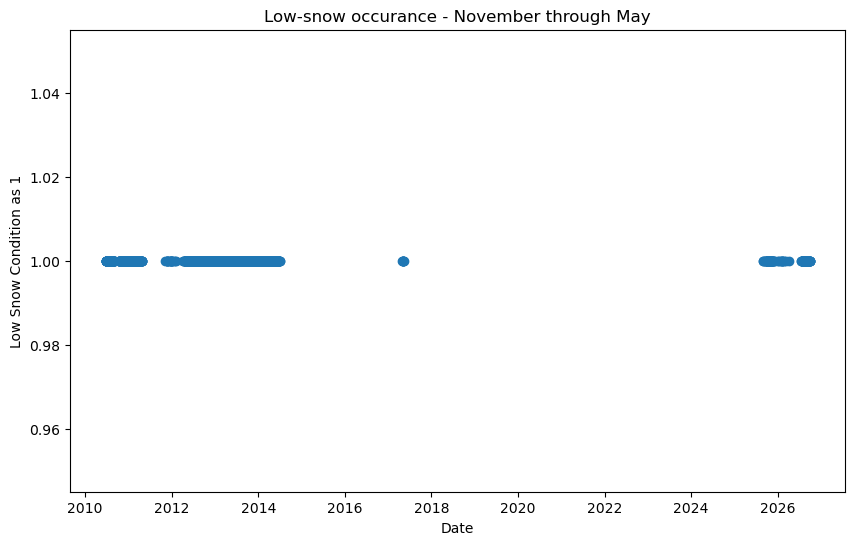

In [7]:
# Visualizing where target variable is 1 i.e there is drought

plt.figure(figsize=(10, 6))
plt.scatter(df[df['target'] == 1]['date'], df[df['target'] == 1]['target'])
plt.title('Low-snow occurance - November through May')
plt.xlabel('Date')
plt.ylabel('Low Snow Condition as 1')
plt.show()

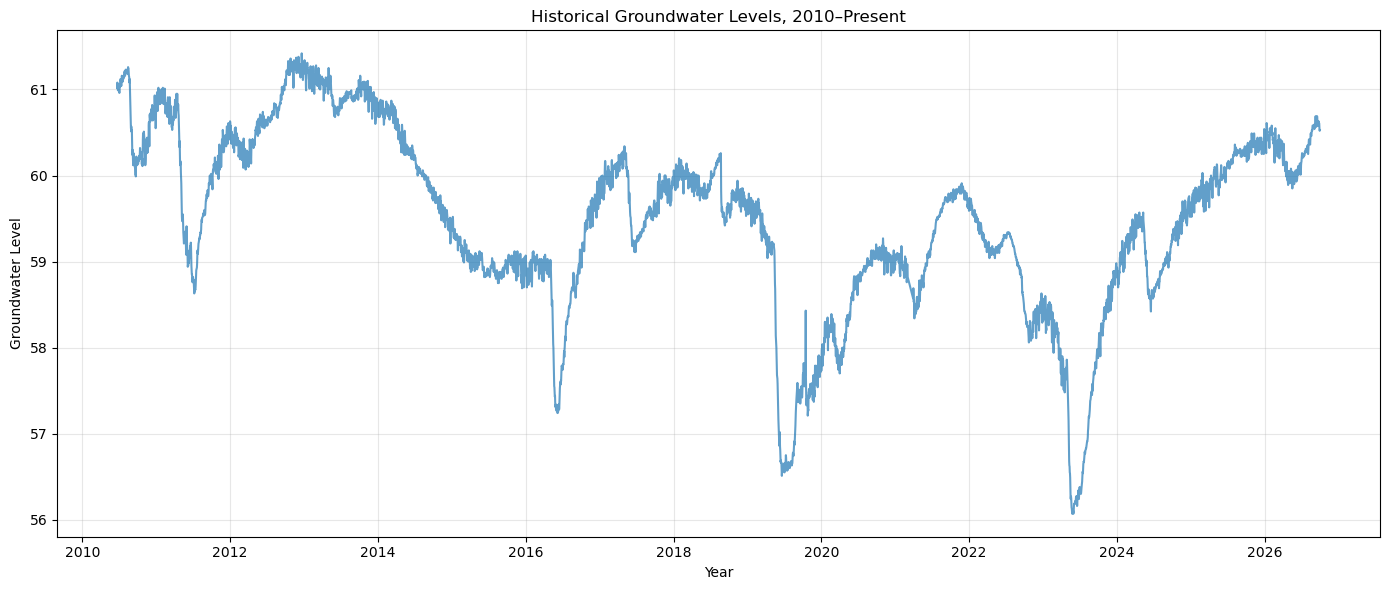

In [8]:

gwl_plot = df[
    df['date'] >= '2010-01-01'
].dropna(subset=['gwl']).copy()

plt.figure(figsize=(14, 6))

plt.plot(
    gwl_plot['date'],
    gwl_plot['gwl'],
    alpha=0.7
)

plt.xlabel('Year')
plt.ylabel('Groundwater Level')
plt.title('Historical Groundwater Levels, 2010–Present')

plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    'figures/historical_groundwater_levels.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

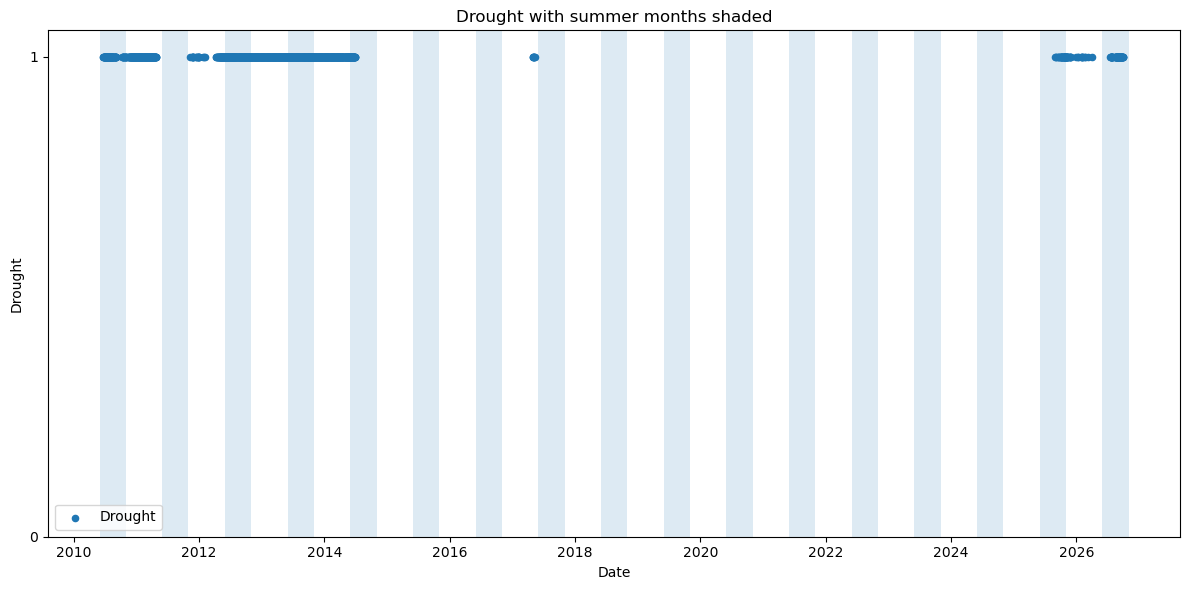

In [9]:
import matplotlib.pyplot as plt
import pandas as pd

plt.figure(figsize=(12, 6))

# Plot low-snow events
plt.scatter(
    df[df['target'] == 1]['date'],
    df[df['target'] == 1]['target'],
    s=20,
    label='Drought'
)

# Shade June through October for each year
years = df['date'].dt.year.unique()

for year in years:
    summer_start = pd.Timestamp(year=year, month=6, day=1)
    summer_end = pd.Timestamp(year=year, month=11, day=1)

    plt.axvspan(
        summer_start,
        summer_end,
        alpha=0.15
    )

plt.title('Drought with summer months shaded')
plt.xlabel('Date')
plt.ylabel('Drought')

plt.yticks([0, 1])
plt.legend()
plt.tight_layout()
plt.show()

In [11]:
features = [
    'basin_swe',
    'swe_30d_lag',
    'swe_60d_lag',
    'swe_90d_lag',
    'temp_14d_mean',
    'precip_30d',
    'precip_90d',
    'precip_180d',
    'doy_sin',
    'doy_cos']

df = df[
    features + ['target']
].dropna().copy()

X = df[features].copy()
y = df['target'].copy()

In [12]:
df.columns

Index(['basin_swe', 'swe_30d_lag', 'swe_60d_lag', 'swe_90d_lag',
       'temp_14d_mean', 'precip_30d', 'precip_90d', 'precip_180d', 'doy_sin',
       'doy_cos', 'target'],
      dtype='object')

In [13]:
# split test train
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=0,
    stratify=y
)

In [14]:
# scaler
scaler = StandardScaler()

In [15]:
# scale x
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [16]:
# svm model
svm_model = SVC(
    kernel='rbf',
    C=1,
    gamma='scale',
    class_weight='balanced',
    probability=True,
    random_state=42
)

svm_model.fit(X_train_scaled, y_train)

SVC(C=1, class_weight='balanced', probability=True, random_state=42)

In [17]:
# evaluate
y_pred = svm_model.predict(X_test_scaled)
y_score = svm_model.decision_function(X_test_scaled)

print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            'No Drought',
            'Drought'
        ]
    )
)

print("ROC-AUC:", roc_auc_score(y_test, y_score))

              precision    recall  f1-score   support

  No Drought       0.96      0.88      0.92       943
     Drought       0.64      0.85      0.73       239

    accuracy                           0.87      1182
   macro avg       0.80      0.87      0.83      1182
weighted avg       0.90      0.87      0.88      1182

ROC-AUC: 0.9433482564769253


In [18]:
# cross validation

from sklearn.model_selection import GridSearchCV

param_grid = {
    'C': [0.1, 0.5, 1, 5, 10],
    'gamma': ['scale', 0.001, 0.01, 0.1, 1],
    'kernel': ['rbf']
}

grid_f1 = GridSearchCV(
    estimator=SVC(
        class_weight='balanced',
        probability=True,
        random_state=42
    ),
    param_grid=param_grid,
    scoring='f1',
    cv=5,
    n_jobs=-1
)

grid_f1.fit(X_train_scaled, y_train)

print("Best CV F1:", grid_f1.best_score_)
print("Best parameters:", grid_f1.best_params_)

Best CV F1: 0.9291936332548889
Best parameters: {'C': 10, 'gamma': 1, 'kernel': 'rbf'}


In [19]:
# final model
best_svm = grid_f1.best_estimator_

y_pred_tuned = best_svm.predict(X_test_scaled)
y_score_tuned = best_svm.decision_function(X_test_scaled)

print(
    classification_report(
        y_test,
        y_pred_tuned,
        target_names=[
            'No Drought',
            'Drought'
        ]
    )
)

print(
    "ROC-AUC:",
    roc_auc_score(y_test, y_score_tuned)
)

              precision    recall  f1-score   support

  No Drought       1.00      0.98      0.99       943
     Drought       0.92      0.98      0.95       239

    accuracy                           0.98      1182
   macro avg       0.96      0.98      0.97      1182
weighted avg       0.98      0.98      0.98      1182

ROC-AUC: 0.9933045519285464


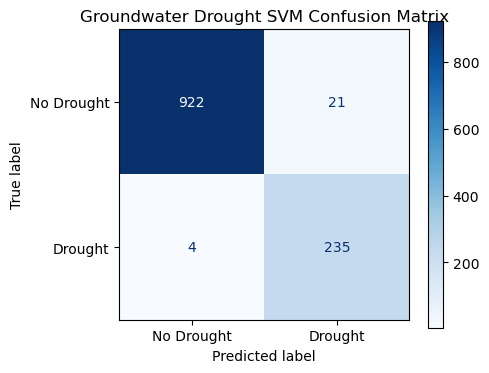

In [26]:
fig, ax = plt.subplots(figsize=(5, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_tuned,
    display_labels=[
        'No Drought',
        'Drought'
    ],
    cmap='Blues',
    ax=ax
)

plt.title('Groundwater Drought SVM Confusion Matrix')
plt.tight_layout()

plt.savefig(
    "figures/svm_gwl_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

SAVE MODEL

In [21]:
import joblib
from pathlib import Path

model_dir = Path("data/models")
model_dir.mkdir(parents=True, exist_ok=True)

svm_bundle = {
    "model": best_svm,
    "scaler": scaler,
    "features": features
}

joblib.dump(
    svm_bundle,
    model_dir / "svm_gwl_bundle.joblib"
)

print("SVM model saved.")

SVM model saved.


To relaod and future RCP data

In [23]:
bundle = joblib.load(
    "data/models/svm_gwl_bundle.joblib"
)

svm_gwl_model = bundle["model"]
svm_gwl_scaler = bundle["scaler"]
features_svm = bundle["features"]

print(features_svm)

['basin_swe', 'temp_mean', 'temp_14d_mean', 'precip_7d', 'precip_14d', 'precip_30d', 'doy_sin', 'doy_cos']


In [25]:
features_svm

['basin_swe',
 'temp_mean',
 'temp_14d_mean',
 'precip_7d',
 'precip_14d',
 'precip_30d',
 'doy_sin',
 'doy_cos']

In [ ]:
X_future = future_df[features]

X_future_scaled = scaler.transform(X_future)

future_df['predicted_low_snow'] = (
    best_svm.predict(X_future_scaled)
)